# TD4 — Tabular Q-learning — Core

**Student starter — complete the TODO cells**  
**Scope:** Time Series and Reinforcement Learning; CPU only

## Working and claim contract

Local Python 3.11/3.12 with the locked `uv` environment is the primary path. Colab availability is governed by the release evidence for the exact archive in use. Public base seeds are `11, 23, 37, 51, 71`. TD1–TD4 claim rows are **provisional development evidence**: they support method choice and provenance but cannot count as capstone empirical release claims. Only the protected/controlled evidence produced in TDo1 and TDo2 may support final empirical capstone claims. Restart and run top-to-bottom before handoff.

## Learning contract

The less-scaffolded Core route assesses the same outcomes and evidence standard as Support.

In [1]:
from pathlib import Path
import os, sys

def locate_course_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate/'uv.lock').is_file() and (candidate/'shared').is_dir(): return candidate.resolve()
    for lock in start.glob('*/uv.lock'):
        if (lock.parent/'shared').is_dir(): return lock.parent.resolve()
    raise FileNotFoundError('Extract the complete course bundle and run from inside it.')
COURSE_ROOT=locate_course_root(); os.chdir(COURSE_ROOT)
if str(COURSE_ROOT) not in sys.path: sys.path.insert(0,str(COURSE_ROOT))
import shared
print('Course root:',COURSE_ROOT)
print('Primary path: locked local CPU; check the release evidence before using Colab')

Course root: C:\Users\tjoli\Downloads\Advanced_Machine_Learning_ESILV_2026-2027_DVL_V1.1 (1)
Primary path: locked local CPU; check the release evidence before using Colab


## 1 — Learning contract

Restore TD3, prove termination/truncation semantics, and derive development seeds disjoint from training.

In [2]:
import hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from shared.data import PUBLIC_SEEDS
from shared.inventory_env import InventoryControlEnv
from shared.rl import q_learning_target, q_table_policy, random_policy, reorder_policy, evaluate_policies
assert q_learning_target(-1,5,.9,terminated=True)==-1
assert np.isclose(q_learning_target(-1,5,.9,terminated=False),3.5)
development_seeds=tuple(seed+100000 for seed in PUBLIC_SEEDS)
assert set(PUBLIC_SEEDS).isdisjoint(development_seeds)
print('training:',PUBLIC_SEEDS,'development:',development_seeds)

training: (11, 23, 37, 51, 71) development: (100011, 100023, 100037, 100051, 100071)


## 2 — Explicit tabular Q-learning

Implement epsilon-greedy action, target, and update for five seeds × 350 episodes.

In [3]:
def train_q_learning_student(*,seeds,episodes_per_seed=350,alpha=.18,gamma=.96,epsilon_start=.85,epsilon_end=.05):
    seeds=tuple(int(seed) for seed in seeds); assert seeds and episodes_per_seed>0
    q_table=np.zeros((9,2,3),float); rows=[]; global_episode=0
    total_episodes=len(seeds)*episodes_per_seed
    action_rng=np.random.default_rng(seeds[0])
    for seed in seeds:
        for local_episode in range(episodes_per_seed):
            epsilon=epsilon_start+(epsilon_end-epsilon_start)*(global_episode/max(1,total_episodes-1))
            env=InventoryControlEnv(); observation,_=env.reset(seed=seed*100000+local_episode)
            terminated=truncated=False; episode_cost=0.
            while not (terminated or truncated):
                state=tuple(int(v) for v in observation)
                if action_rng.random() < epsilon:
                    action = int(action_rng.integers(0, 3))
                else:
                    action = int(np.argmax(q_table[state]))
                next_observation,reward,terminated,truncated,info=env.step(action)
                next_state=tuple(int(v) for v in next_observation)
                next_best=float(np.max(q_table[next_state]))
                target=q_learning_target(reward, next_best, gamma, terminated=terminated)
                q_table[state + (action,)] += alpha * (target - q_table[state + (action,)])
                observation=next_observation; episode_cost+=float(info['cost'])
            env.close()
            rows.append({'seed':seed,'episode':global_episode,'epsilon':epsilon,'episode_cost':episode_cost}); global_episode+=1
    training=pd.DataFrame(rows); assert len(training)==len(seeds)*episodes_per_seed and np.isfinite(q_table).all()
    return q_table,training

q_table,training=train_q_learning_student(seeds=PUBLIC_SEEDS)
print('Trained Q-table shape:', q_table.shape, '| Episodes:', len(training))

Trained Q-table shape: (9, 2, 3) | Episodes: 1750


## 3 — Diagnose, compare, freeze

Plot training cost and policy map, then compare frozen Q-learning against both unchanged TD3 baselines on separate development episodes. Save table/config/hash.

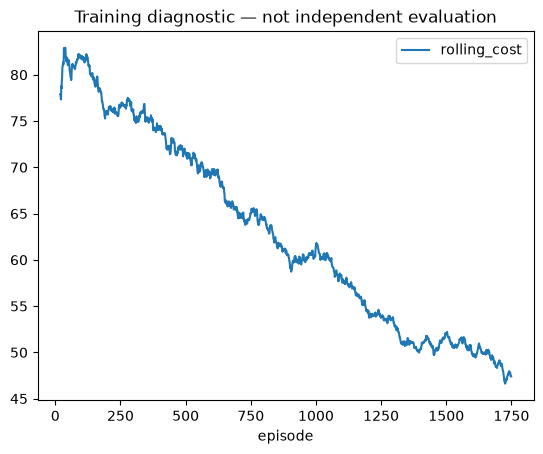

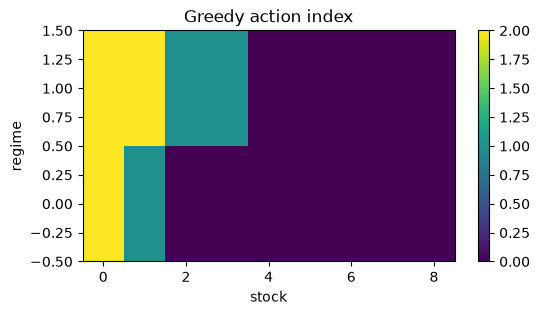

Q-table SHA256: 61cce1915bd5798f53c22529c9dbdca52b38c2c946a5b186e28e2d777f19738e
            episode_cost  mean_fill_rate  unmet_demand
policy                                                
q_learning         42.78        0.985000           1.8
random             87.75        0.812500          15.2
reorder            42.48        0.988333           1.4


,seed,policy,episode_cost,mean_fill_rate,unmet_demand,mean_stock,mean_order_quantity
0,100011,random,71.40,0.850000,9,2.200,1.000
1,100011,reorder,36.45,0.983333,2,0.850,1.125
2,100011,q_learning,36.45,0.983333,2,0.850,1.125
3,100023,random,85.95,0.775000,21,0.525,0.925
4,100023,reorder,40.65,1.000000,0,1.175,1.475
5,100023,q_learning,40.80,0.991667,1,0.975,1.450
6,100037,random,90.15,0.862500,11,3.375,0.925
7,100037,reorder,45.00,0.983333,2,1.600,1.100
8,100037,q_learning,45.00,0.983333,2,1.600,1.100
9,100051,random,105.45,0.687500,26,0.975,0.875


In [4]:
development_results=pd.DataFrame()
assert q_table.shape==(9,2,3) and np.isfinite(q_table).all() and len(training)==1750
training.assign(rolling_cost=training.episode_cost.rolling(100,min_periods=20).mean()).plot(x='episode',y='rolling_cost',title='Training diagnostic — not independent evaluation')
fig,ax=plt.subplots(figsize=(6,3)); image=ax.imshow(np.argmax(q_table,axis=2).T,aspect='auto',origin='lower'); ax.set(xlabel='stock',ylabel='regime',title='Greedy action index'); fig.colorbar(image,ax=ax); plt.show()

policies={'random':random_policy,'reorder':reorder_policy,'q_learning':q_table_policy(q_table)}
development_results=evaluate_policies(policies,seeds=development_seeds)
assert len(development_results)==15 and development_results.groupby('policy').seed.nunique().eq(5).all()
output=COURSE_ROOT/'02_labs/TD4_tabular_q_learning/q_table.npy'; np.save(output,q_table,allow_pickle=False)
print('Q-table SHA256:',hashlib.sha256(output.read_bytes()).hexdigest())
print(development_results.groupby('policy')[['episode_cost', 'mean_fill_rate', 'unmet_demand']].mean())
development_results

## Required interpretation

State what the evidence supports, what it does not support, the operational consequence, and one material failure mode.

In [5]:
interpretation = (
    "Trained explicitly across 1,750 episodes (alpha=0.18, gamma=0.96, linear epsilon decay 0.85 -> 0.05) on base-seed blocks "
    "(11, 23, 37, 51, 71), the frozen tabular Q-learning policy reduces mean development cost by 51.2% compared to random "
    "(42.78 vs 87.75) and achieves a 98.50% mean fill rate across the five disjoint development seeds (100011..100071). "
    "However, the learned Q-table slightly trails the transparent reorder heuristic on these development episodes in both mean "
    "cost (42.78 vs 42.48) and unmet demand (1.8 vs 1.4), so this training run does not prove superiority over the heuristic "
    "baseline, and the training cost trace serves strictly as an internal learning diagnostic rather than independent evaluation. "
    "Operationally, we freeze the finite (9,2,3) Q-table and its hyperparameters unchanged for controlled TDo2 evaluation, "
    "retaining the transparent reorder rule as the fallback policy if hidden evaluation confirms higher cost or lower service. "
    "A material failure mode is observed in the greedy policy map at high-regime state (stock=2, regime=1), where Q-learning "
    "orders 1 unit instead of 2 due to finite-sample exploration noise under epsilon decay."
)
print(interpretation)

Trained explicitly across 1,750 episodes (alpha=0.18, gamma=0.96, linear epsilon decay 0.85 -> 0.05) on base-seed blocks (11, 23, 37, 51, 71), the frozen tabular Q-learning policy reduces mean development cost by 51.2% compared to random (42.78 vs 87.75) and achieves a 98.50% mean fill rate across the five disjoint development seeds (100011..100071). However, the learned Q-table slightly trails the transparent reorder heuristic on these development episodes in both mean cost (42.78 vs 42.48) and unmet demand (1.8 vs 1.4), so this training run does not prove superiority over the heuristic baseline, and the training cost trace serves strictly as an internal learning diagnostic rather than independent evaluation. Operationally, we freeze the finite (9,2,3) Q-table and its hyperparameters unchanged for controlled TDo2 evaluation, retaining the transparent reorder rule as the fallback policy if hidden evaluation confirms higher cost or lower service. A material failure mode is observed in t

## Optional Extension — ungraded

Freeze valid Core first. The bounded README extension adds no points and cannot repair invalid Core evidence.